In [1]:
import os
from pathlib import Path

import polars as pl
from dotenv import load_dotenv
from IPython.display import HTML, IFrame
from pyecharts import options as opts
from pyecharts.charts import TreeMap, Polar

from preprocessing import procesar_generacion_energia_treemap, procesar_generacion_energia_nightingale_chart, root_path
from utils import df_to_tree

load_dotenv()


True

# Gráfica 1: Treemap.

In [7]:

procesar_generacion_energia_treemap()

datos_generacion = pl.read_parquet( root_path / "data" / "interim" / "estructura_generacion_electrica.parquet")

datos_treemap = df_to_tree(datos_generacion, ["Es renovable", "Tipo energía"], "Porcentaje Generación")

treemap = (
    TreeMap(init_opts=opts.InitOpts(width="100%", height="600px"))
    .add(
        series_name="% Energía Total",
        data=datos_treemap,
        leaf_depth=1,
        label_opts= {"position": "inside", "fontSize": 13, "formatter": "{b} ({c}%)"},
    )
    .set_colors(["#7bc98f", "#e07a7a"])
    .set_global_opts(
        legend_opts={"show": False},
        title_opts={"text": "% de electricidad generada por tipo de energía (2026)", 
                    "left":"center"},
        tooltip_opts={"trigger": "item", "left":"left"},
    )
)

ruta_guardado = "../reports/grafica_treemap.html"
treemap.render(ruta_guardado)

IFrame(src=ruta_guardado, width=900, height=700)

# Gráfica 2: Nightingale Chart

In [8]:

procesar_generacion_energia_nightingale_chart()

datos_generacion_mes = pl.read_parquet( root_path / "data" / "interim" / "estructura_generacion_electrica_nightingale_chart.parquet")


MESES_ESTUDIO = (
    datos_generacion_mes.select("Número de mes", "Mes")
    .unique()
    .sort("Número de mes")["Mes"]
    .to_list()
)

COLORES = {"Renovable": "#66bb6a", "Nuclear": "#f4b183", "No renovable": "#e57373"}


df_energias = (
    datos_generacion_mes
    .group_by("Número de mes", "Es renovable")
    .agg(pl.col("Generación").sum())
    .pivot(on="Es renovable", index="Número de mes", values="Generación")
    .sort("Número de mes")
)

orden = ["No renovable", "Nuclear", "Renovable"]

grafica_polar = Polar(init_opts= opts.InitOpts(width="1005", height="650px"))
grafica_polar.add_schema(
    angleaxis_opts={"type": "category", "data":MESES_ESTUDIO, "clockwise":True},
    radiusaxis_opts={"min":0}
)

for energia in orden:
    grafica_polar.add(
        series_name = energia,
        data = df_energias[energia].to_list(),
        type_="bar",
        label_opts={"show":False},
        stack="total"
    )

grafica_polar.set_colors([COLORES[energia] for energia in orden])

grafica_polar.set_global_opts(
    title_opts={"text":"Generación (GWh) al mes por tipo de energía", "left":"center"},
    legend_opts={"left": "left", "orient": "vertical"},
    tooltip_opts={"trigger": "axis"}
)

ruta_guardado = "../reports/grafica_nightingale.html"
grafica_polar.render(ruta_guardado)

IFrame(src=ruta_guardado, width=900, height=700)

# Gráfica 3: Violin Plot

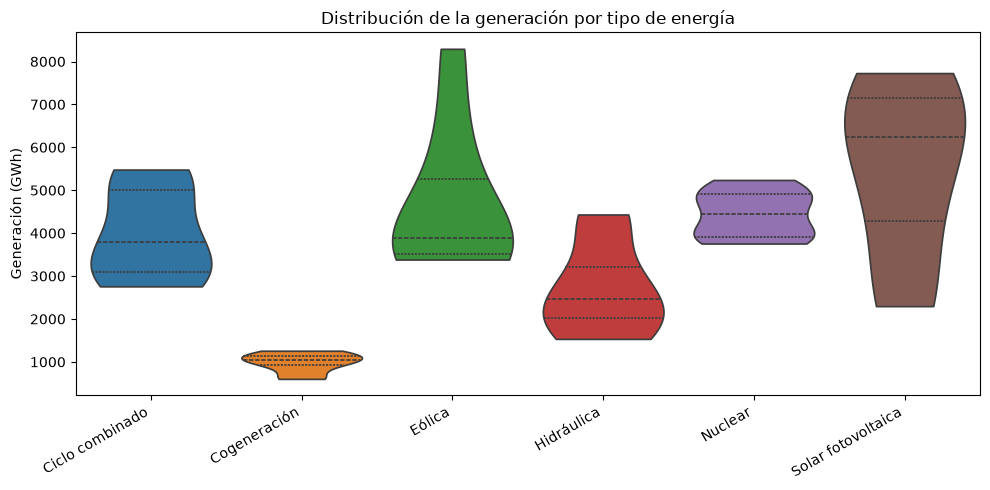

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

#Graficar únicamente los 6 más importantes
top_6 = (
    datos_generacion_mes
    .group_by("Tipo energía")
    .agg(pl.sum("Generación")
        .alias("Producción total"))
    .sort("Producción total")
    .tail(6)
)

datos_violin_plot = datos_generacion_mes.join(top_6.select("Tipo energía"), on="Tipo energía", how="inner")

fig, ax = plt.subplots(figsize=(10, 5))

sns.violinplot(
    data=datos_violin_plot.to_pandas(),
    x="Tipo energía",
    y="Generación",
    hue="Tipo energía",
    inner="quartile",
    cut=0,
    density_norm="width",
    legend=False,
    ax=ax,
)

ax.set_title("Distribución de la generación por tipo de energía")
ax.set_xlabel("")
ax.set_ylabel("Generación (GWh)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()